In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(
        r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
    )

os.chdir(PROJECT_ROOT)

REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
CHART_DIR = PROJECT_ROOT / "outputs" / "charts"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Risk analytics environment ready.")

Project: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Risk analytics environment ready.


In [2]:
TRADES_FILE = REPORT_DIR / "backtest_trade_log.csv"
DAILY_FILE = REPORT_DIR / "backtest_daily_portfolio.csv"
PERFORMANCE_FILE = REPORT_DIR / "backtest_performance_summary.csv"

required_files = [
    TRADES_FILE,
    DAILY_FILE,
    PERFORMANCE_FILE
]

for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f"Required Notebook 10 output missing: {file}"
        )

trades = pd.read_csv(TRADES_FILE)
daily = pd.read_csv(DAILY_FILE)
performance = pd.read_csv(PERFORMANCE_FILE)

print("Trades loaded:", len(trades))
print("Daily records loaded:", len(daily))

display(trades.head())
display(daily.head())
display(performance)

Trades loaded: 94
Daily records loaded: 208


,Instrument,Model,Signal_Date,Trade_Date,Signal,Predicted_Return_Pct,Entry_Price,Stop_Loss,Target,Exit_Price,Exit_Reason,Quantity,Risk_Budget,Gross_PnL,Transaction_Cost,Net_PnL,Return_on_Notional_Pct,Equity_Before_Trade,Equity_After_Trade
0,HDFCBANK,Gradient Boosting,2026-01-27,2026-01-28,SELL,-0.301642,932.500000,955.233725,898.399413,932.700012,SESSION_CLOSE,35,1000.000000,-7.000427,52.225600,-59.226028,-0.181466,100000.000000,99940.773972
1,RELIANCE,Gradient Boosting,2026-01-28,2026-01-29,SELL,-0.277891,1402.900024,1443.983839,1341.274302,1391.000000,SESSION_CLOSE,23,999.407740,273.700562,51.407760,222.292801,0.688923,99940.773972,100163.066773
2,ITC,Linear Regression,2026-02-02,2026-02-03,BUY,2.506678,321.200012,310.156837,337.764774,316.649994,SESSION_CLOSE,90,1001.630668,-409.501648,45.925200,-455.426848,-1.575435,100163.066773,99707.639925
3,RELIANCE,Gradient Boosting,2026-02-02,2026-02-03,SELL,-0.328801,1473.900024,1516.897985,1409.403083,1437.099976,SESSION_CLOSE,22,997.076399,809.601074,51.233600,758.367474,2.338778,99707.639925,100466.007399
4,ITC,Linear Regression,2026-02-04,2026-02-05,BUY,0.661441,313.950012,302.551945,331.047113,310.200012,SESSION_CLOSE,88,1004.660074,-330.000000,43.940162,-373.940162,-1.353502,100466.007399,100092.067238


,Date,Starting_Equity,Daily_PnL,Trades,Ending_Equity,Daily_Return_Pct,Cumulative_Peak,Drawdown_Pct
0,2026-01-19,100000.0,0.0,0,100000.0,0.0,100000.0,0.0
1,2026-01-20,100000.0,0.0,0,100000.0,0.0,100000.0,0.0
2,2026-01-21,100000.0,0.0,0,100000.0,0.0,100000.0,0.0
3,2026-01-22,100000.0,0.0,0,100000.0,0.0,100000.0,0.0
4,2026-01-23,100000.0,0.0,0,100000.0,0.0,100000.0,0.0


,Initial_Capital,Final_Capital,Net_Profit,Total_Return_Pct,Total_Trades,Winning_Trades,Losing_Trades,Win_Rate_Pct,Gross_Profit,Gross_Loss,Profit_Factor,Average_Trade_PnL,Best_Trade,Worst_Trade,Maximum_Drawdown_Pct,Sharpe_Ratio
0,100000,103876.62367,3876.62367,3.876624,94,47,47,50.0,15233.900792,11357.277123,1.341334,41.240677,1403.780844,-1013.414302,-2.412466,1.143404


In [3]:
required_trade_columns = [
    "Instrument",
    "Signal",
    "Trade_Date",
    "Entry_Price",
    "Exit_Price",
    "Quantity",
    "Risk_Budget",
    "Gross_PnL",
    "Transaction_Cost",
    "Net_PnL"
]

required_daily_columns = [
    "Date",
    "Starting_Equity",
    "Daily_PnL",
    "Trades",
    "Ending_Equity"
]

missing_trade = [
    c for c in required_trade_columns if c not in trades.columns
]

missing_daily = [
    c for c in required_daily_columns if c not in daily.columns
]

if missing_trade:
    raise ValueError(f"Missing trade columns: {missing_trade}")

if missing_daily:
    raise ValueError(f"Missing daily columns: {missing_daily}")

trades["Trade_Date"] = pd.to_datetime(
    trades["Trade_Date"], errors="coerce"
)

daily["Date"] = pd.to_datetime(
    daily["Date"], errors="coerce"
)

numeric_trade_columns = [
    "Entry_Price", "Exit_Price", "Quantity",
    "Risk_Budget", "Gross_PnL",
    "Transaction_Cost", "Net_PnL"
]

for col in numeric_trade_columns:
    trades[col] = pd.to_numeric(
        trades[col], errors="coerce"
    )

numeric_daily_columns = [
    "Starting_Equity",
    "Daily_PnL",
    "Trades",
    "Ending_Equity"
]

for col in numeric_daily_columns:
    daily[col] = pd.to_numeric(
        daily[col], errors="coerce"
    )

trades = trades.dropna(
    subset=["Trade_Date", "Net_PnL"]
).sort_values("Trade_Date").reset_index(drop=True)

daily = daily.dropna(
    subset=["Date", "Starting_Equity", "Daily_PnL", "Ending_Equity"]
).sort_values("Date").reset_index(drop=True)

if daily.empty:
    raise ValueError("Daily portfolio dataset is empty.")

INITIAL_CAPITAL = float(daily.iloc[0]["Starting_Equity"])

RISK_PER_TRADE_PCT = 1.0
MAX_DAILY_LOSS_PCT = 2.0

print("Data validation completed.")
print("Initial capital:", INITIAL_CAPITAL)
print("Trade records:", len(trades))
print("Trading sessions:", len(daily))
print("Date range:", daily["Date"].min().date(), "to", daily["Date"].max().date())

Data validation completed.
Initial capital: 100000.0
Trade records: 94
Trading sessions: 208
Date range: 2026-01-19 to 2026-11-23


In [4]:
daily["Daily_Return"] = (
    daily["Daily_PnL"] / daily["Starting_Equity"]
)

daily["Daily_Return_Pct"] = daily["Daily_Return"] * 100

# Reconstruct equity from the initial capital and daily realised P&L.
daily["Reconstructed_Equity"] = (
    INITIAL_CAPITAL + daily["Daily_PnL"].cumsum()
)

daily["Equity_Peak"] = np.maximum.accumulate(
    np.r_[INITIAL_CAPITAL, daily["Reconstructed_Equity"].values]
)[1:]

daily["Drawdown"] = (
    daily["Reconstructed_Equity"] / daily["Equity_Peak"] - 1
)

daily["Drawdown_Pct"] = daily["Drawdown"] * 100

daily["Daily_Loss_Limit"] = (
    daily["Starting_Equity"] * MAX_DAILY_LOSS_PCT / 100
)

daily["Daily_Loss_Limit_Used_Pct"] = (
    -daily["Daily_PnL"].clip(upper=0) /
    daily["Daily_Loss_Limit"].replace(0, np.nan)
) * 100

print("Reconstructed final equity: ₹{:,.2f}".format(
    daily["Reconstructed_Equity"].iloc[-1]
))

print("Recorded final equity: ₹{:,.2f}".format(
    daily["Ending_Equity"].iloc[-1]
))

display(
    daily[
        [
            "Date",
            "Starting_Equity",
            "Daily_PnL",
            "Reconstructed_Equity",
            "Drawdown_Pct"
        ]
    ].head()
)

Reconstructed final equity: ₹103,876.62
Recorded final equity: ₹103,876.62


,Date,Starting_Equity,Daily_PnL,Reconstructed_Equity,Drawdown_Pct
0,2026-01-19,100000.0,0.0,100000.0,0.0
1,2026-01-20,100000.0,0.0,100000.0,0.0
2,2026-01-21,100000.0,0.0,100000.0,0.0
3,2026-01-22,100000.0,0.0,100000.0,0.0
4,2026-01-23,100000.0,0.0,100000.0,0.0


In [5]:
daily["Daily_Loss_Pct"] = (
    daily["Daily_PnL"].clip(upper=0) /
    daily["Starting_Equity"]
) * 100

daily["Daily_Loss_Breach"] = (
    daily["Daily_Loss_Pct"] < -MAX_DAILY_LOSS_PCT
)

breach_days = daily[daily["Daily_Loss_Breach"]].copy()

daily_loss_summary = pd.DataFrame([{
    "Trading_Sessions": len(daily),
    "Sessions_With_Loss": int((daily["Daily_PnL"] < 0).sum()),
    "Maximum_Daily_Loss_Pct": daily["Daily_Loss_Pct"].min(),
    "Daily_Loss_Limit_Pct": MAX_DAILY_LOSS_PCT,
    "Breach_Days": len(breach_days),
    "Daily_Limit_Compliance_Pct": (
        100 * (1 - len(breach_days) / len(daily))
    )
}])

display(daily_loss_summary)

if not breach_days.empty:
    print("WARNING: Daily loss limit was exceeded on these dates:")
    display(
        breach_days[
            ["Date", "Starting_Equity", "Daily_PnL", "Daily_Loss_Pct"]
        ]
    )
else:
    print("No realised daily loss-limit breaches detected.")

,Trading_Sessions,Sessions_With_Loss,Maximum_Daily_Loss_Pct,Daily_Loss_Limit_Pct,Breach_Days,Daily_Limit_Compliance_Pct
0,208,42,-1.009187,2.0,0,100.0


No realised daily loss-limit breaches detected.


In [6]:
trades["Actual_Loss"] = (
    -trades["Net_PnL"].clip(upper=0)
)

trades["Risk_Used_Pct"] = (
    trades["Actual_Loss"] /
    trades["Risk_Budget"].replace(0, np.nan)
) * 100

trades["Risk_Budget_Exceeded"] = (
    trades["Actual_Loss"] > trades["Risk_Budget"]
)

trades["Entry_Notional"] = (
    trades["Entry_Price"] * trades["Quantity"]
)

trades["Notional_to_Equity_Pct"] = (
    trades["Entry_Notional"] /
    trades["Equity_Before_Trade"].replace(0, np.nan)
) * 100 if "Equity_Before_Trade" in trades.columns else np.nan

risk_summary = pd.DataFrame([{
    "Total_Trades": len(trades),
    "Average_Risk_Budget": trades["Risk_Budget"].mean(),
    "Average_Entry_Notional": trades["Entry_Notional"].mean(),
    "Average_Notional_Pct": trades["Notional_to_Equity_Pct"].mean(),
    "Loss_Making_Trades": int((trades["Net_PnL"] < 0).sum()),
    "Losses_Exceeding_Risk_Budget": int(
        trades["Risk_Budget_Exceeded"].sum()
    ),
    "Maximum_Risk_Used_Pct": trades["Risk_Used_Pct"].max()
}])

display(risk_summary.T.rename(columns={0: "Value"}))

print("Largest losses compared with planned risk:")
display(
    trades.sort_values("Risk_Used_Pct", ascending=False)[
        [
            "Instrument", "Trade_Date", "Signal",
            "Risk_Budget", "Net_PnL",
            "Risk_Used_Pct", "Risk_Budget_Exceeded"
        ]
    ].head(10)
)

,Value
Total_Trades,94.000000
Average_Risk_Budget,1008.147700
Average_Entry_Notional,30273.369829
Average_Notional_Pct,30.031472
Loss_Making_Trades,47.000000
Losses_Exceeding_Risk_Budget,1.000000
Maximum_Risk_Used_Pct,100.918715


Largest losses compared with planned risk:


,Instrument,Trade_Date,Signal,Risk_Budget,Net_PnL,Risk_Used_Pct,Risk_Budget_Exceeded
25,RELIANCE,2026-03-27,BUY,1004.188673,-1013.414302,100.918715,True
81,RELIANCE,2026-10-28,BUY,1015.647690,-997.932000,98.255725,False
12,RELIANCE,2026-03-11,BUY,1006.586738,-702.090911,69.749668,False
58,HDFCBANK,2026-08-27,BUY,1011.464994,-702.255432,69.429534,False
69,ITC,2026-09-16,SELL,1006.316680,-661.611519,65.745856,False
37,RELIANCE,2026-05-12,BUY,1021.811437,-604.096000,59.120106,False
2,ITC,2026-02-03,BUY,1001.630668,-455.426848,45.468541,False
4,ITC,2026-02-05,BUY,1004.660074,-373.940162,37.220566,False
73,ITC,2026-10-06,BUY,1013.356252,-332.882832,32.849536,False
55,ITC,2026-08-13,SELL,1009.419979,-329.249736,32.617715,False


In [7]:
returns = daily["Daily_Return"].dropna()

annualized_volatility = (
    returns.std(ddof=1) * np.sqrt(252) * 100
    if len(returns) > 1 else np.nan
)

annualized_return = (
    (daily["Reconstructed_Equity"].iloc[-1] / INITIAL_CAPITAL)
    ** (252 / len(daily)) - 1
) * 100 if len(daily) > 0 else np.nan

risk_free_rate_annual = 0.0
risk_free_rate_daily = risk_free_rate_annual / 252

excess_returns = returns - risk_free_rate_daily

sharpe_ratio = (
    excess_returns.mean() / excess_returns.std(ddof=1) * np.sqrt(252)
    if len(excess_returns) > 1 and excess_returns.std(ddof=1) > 0
    else np.nan
)

downside_returns = np.minimum(
    returns - risk_free_rate_daily, 0
)

downside_deviation = np.sqrt(
    np.mean(downside_returns ** 2)
) if len(downside_returns) else np.nan

sortino_ratio = (
    (returns.mean() - risk_free_rate_daily) /
    downside_deviation * np.sqrt(252)
    if pd.notna(downside_deviation) and downside_deviation > 0
    else np.nan
)

max_drawdown_pct = daily["Drawdown_Pct"].min()

volatility_summary = pd.DataFrame([{
    "Annualized_Return_Pct": annualized_return,
    "Annualized_Volatility_Pct": annualized_volatility,
    "Sharpe_Ratio": sharpe_ratio,
    "Sortino_Ratio": sortino_ratio,
    "Maximum_Drawdown_Pct": max_drawdown_pct,
    "Risk_Free_Rate_Pct": risk_free_rate_annual
}])

display(volatility_summary.T.rename(columns={0: "Value"}))

,Value
Annualized_Return_Pct,4.715743
Annualized_Volatility_Pct,4.103496
Sharpe_Ratio,1.143404
Sortino_Ratio,1.962091
Maximum_Drawdown_Pct,-2.412466
Risk_Free_Rate_Pct,0.000000


In [8]:
instrument_risk = (
    trades.groupby("Instrument")
    .agg(
        Total_Trades=("Net_PnL", "count"),
        Net_PnL=("Net_PnL", "sum"),
        Average_PnL=("Net_PnL", "mean"),
        Total_Gross_PnL=("Gross_PnL", "sum"),
        Total_Cost=("Transaction_Cost", "sum"),
        Total_Entry_Notional=("Entry_Notional", "sum"),
        Winning_Trades=("Net_PnL", lambda x: (x > 0).sum()),
        Losing_Trades=("Net_PnL", lambda x: (x < 0).sum())
    )
    .reset_index()
)

instrument_risk["Win_Rate_Pct"] = (
    instrument_risk["Winning_Trades"] /
    instrument_risk["Total_Trades"] * 100
)

instrument_risk["Profit_Contribution_Pct"] = (
    instrument_risk["Net_PnL"] /
    trades["Net_PnL"].sum() * 100
    if trades["Net_PnL"].sum() != 0 else np.nan
)

instrument_risk["Average_Entry_Notional"] = (
    instrument_risk["Total_Entry_Notional"] /
    instrument_risk["Total_Trades"]
)

instrument_risk = instrument_risk.sort_values(
    "Net_PnL", ascending=False
)

display(instrument_risk)

,Instrument,Total_Trades,Net_PnL,Average_PnL,Total_Gross_PnL,Total_Cost,Total_Entry_Notional,Winning_Trades,Losing_Trades,Win_Rate_Pct,Profit_Contribution_Pct,Average_Entry_Notional
2,RELIANCE,42,3239.656145,77.134670,5141.895741,1902.239596,1.187412e+06,23,19,54.761905,83.569013,28271.716692
1,ITC,37,601.864666,16.266613,2495.551514,1893.686848,1.183267e+06,17,20,45.945946,15.525486,31980.184065
0,HDFCBANK,15,35.102859,2.340191,795.401824,760.298965,4.750179e+05,7,8,46.666667,0.905501,31667.856832


In [9]:
def calculate_streaks(pnl_series):

    outcomes = np.where(
        pnl_series > 0, "WIN",
        np.where(pnl_series < 0, "LOSS", "BREAKEVEN")
    )

    streaks = []
    current_outcome = None
    current_length = 0

    for outcome in outcomes:

        if outcome == "BREAKEVEN":
            if current_outcome is not None:
                streaks.append((current_outcome, current_length))
            current_outcome = None
            current_length = 0
            continue

        if outcome == current_outcome:
            current_length += 1

        else:
            if current_outcome is not None:
                streaks.append((current_outcome, current_length))

            current_outcome = outcome
            current_length = 1

    if current_outcome is not None:
        streaks.append((current_outcome, current_length))

    win_streaks = [
        length for outcome, length in streaks
        if outcome == "WIN"
    ]

    loss_streaks = [
        length for outcome, length in streaks
        if outcome == "LOSS"
    ]

    return {
        "Maximum_Consecutive_Wins": max(win_streaks, default=0),
        "Maximum_Consecutive_Losses": max(loss_streaks, default=0),
        "Average_Win_Streak": (
            np.mean(win_streaks) if win_streaks else 0
        ),
        "Average_Loss_Streak": (
            np.mean(loss_streaks) if loss_streaks else 0
        )
    }


streak_results = calculate_streaks(trades["Net_PnL"])

streak_summary = pd.DataFrame([
    streak_results
])

display(streak_summary.T.rename(columns={0: "Value"}))

,Value
Maximum_Consecutive_Wins,5.000000
Maximum_Consecutive_Losses,4.000000
Average_Win_Streak,1.740741
Average_Loss_Streak,1.678571


In [10]:
var_95_return = np.percentile(
    returns, 5
) if len(returns) else np.nan

cvar_95_return = (
    returns[returns <= var_95_return].mean()
    if len(returns) else np.nan
)

var_95_amount = (
    abs(var_95_return) * INITIAL_CAPITAL
    if pd.notna(var_95_return) else np.nan
)

cvar_95_amount = (
    abs(cvar_95_return) * INITIAL_CAPITAL
    if pd.notna(cvar_95_return) else np.nan
)

var_summary = pd.DataFrame([{
    "Historical_VaR_95_Daily_Pct": var_95_return * 100,
    "Historical_CVaR_95_Daily_Pct": cvar_95_return * 100,
    "VaR_95_Approx_Rupees_On_Initial_Capital": var_95_amount,
    "CVaR_95_Approx_Rupees_On_Initial_Capital": cvar_95_amount
}])

display(var_summary.T.rename(columns={0: "Value"}))

,Value
Historical_VaR_95_Daily_Pct,-0.295289
Historical_CVaR_95_Daily_Pct,-0.547130
VaR_95_Approx_Rupees_On_Initial_Capital,295.289245
CVaR_95_Approx_Rupees_On_Initial_Capital,547.129851


In [11]:
monthly = daily.copy()

monthly["Month"] = (
    monthly["Date"].dt.to_period("M").astype(str)
)

monthly_risk = (
    monthly.groupby("Month")
    .agg(
        Starting_Equity=("Starting_Equity", "first"),
        Ending_Equity=("Reconstructed_Equity", "last"),
        Monthly_PnL=("Daily_PnL", "sum"),
        Trading_Sessions=("Date", "count"),
        Trading_Days_With_Trades=("Trades", lambda x: (x > 0).sum())
    )
    .reset_index()
)

monthly_risk["Monthly_Return_Pct"] = (
    monthly_risk["Monthly_PnL"] /
    monthly_risk["Starting_Equity"] * 100
)

monthly_risk["Monthly_Volatility_Pct"] = (
    monthly.groupby("Month")["Daily_Return_Pct"]
    .std()
    .values
)

display(monthly_risk)

,Month,Starting_Equity,Ending_Equity,Monthly_PnL,Trading_Sessions,Trading_Days_With_Trades,Monthly_Return_Pct,Monthly_Volatility_Pct
0,2026-01,100000.000000,100163.066773,163.066773,9,2,0.163067,0.079074
1,2026-02,100163.066773,99940.719980,-222.346794,20,6,-0.221985,0.125306
2,2026-03,99940.719980,99533.834134,-406.885846,19,16,-0.407127,0.367508
3,2026-04,99533.834134,101495.268870,1961.434736,20,8,1.970621,0.327063
4,2026-05,101495.268870,101445.764901,-49.503969,19,8,-0.048775,0.216660
5,2026-06,101445.764901,100847.505015,-598.259886,21,6,-0.589734,0.087100
6,2026-07,100847.505015,100941.997899,94.492884,23,5,0.093699,0.078068
7,2026-08,100941.997899,100444.243949,-497.753951,21,4,-0.493109,0.209418
8,2026-09,100444.243949,100387.336436,-56.907513,21,10,-0.056656,0.213194
9,2026-10,100387.336436,100546.932913,159.596478,20,10,0.158981,0.340075


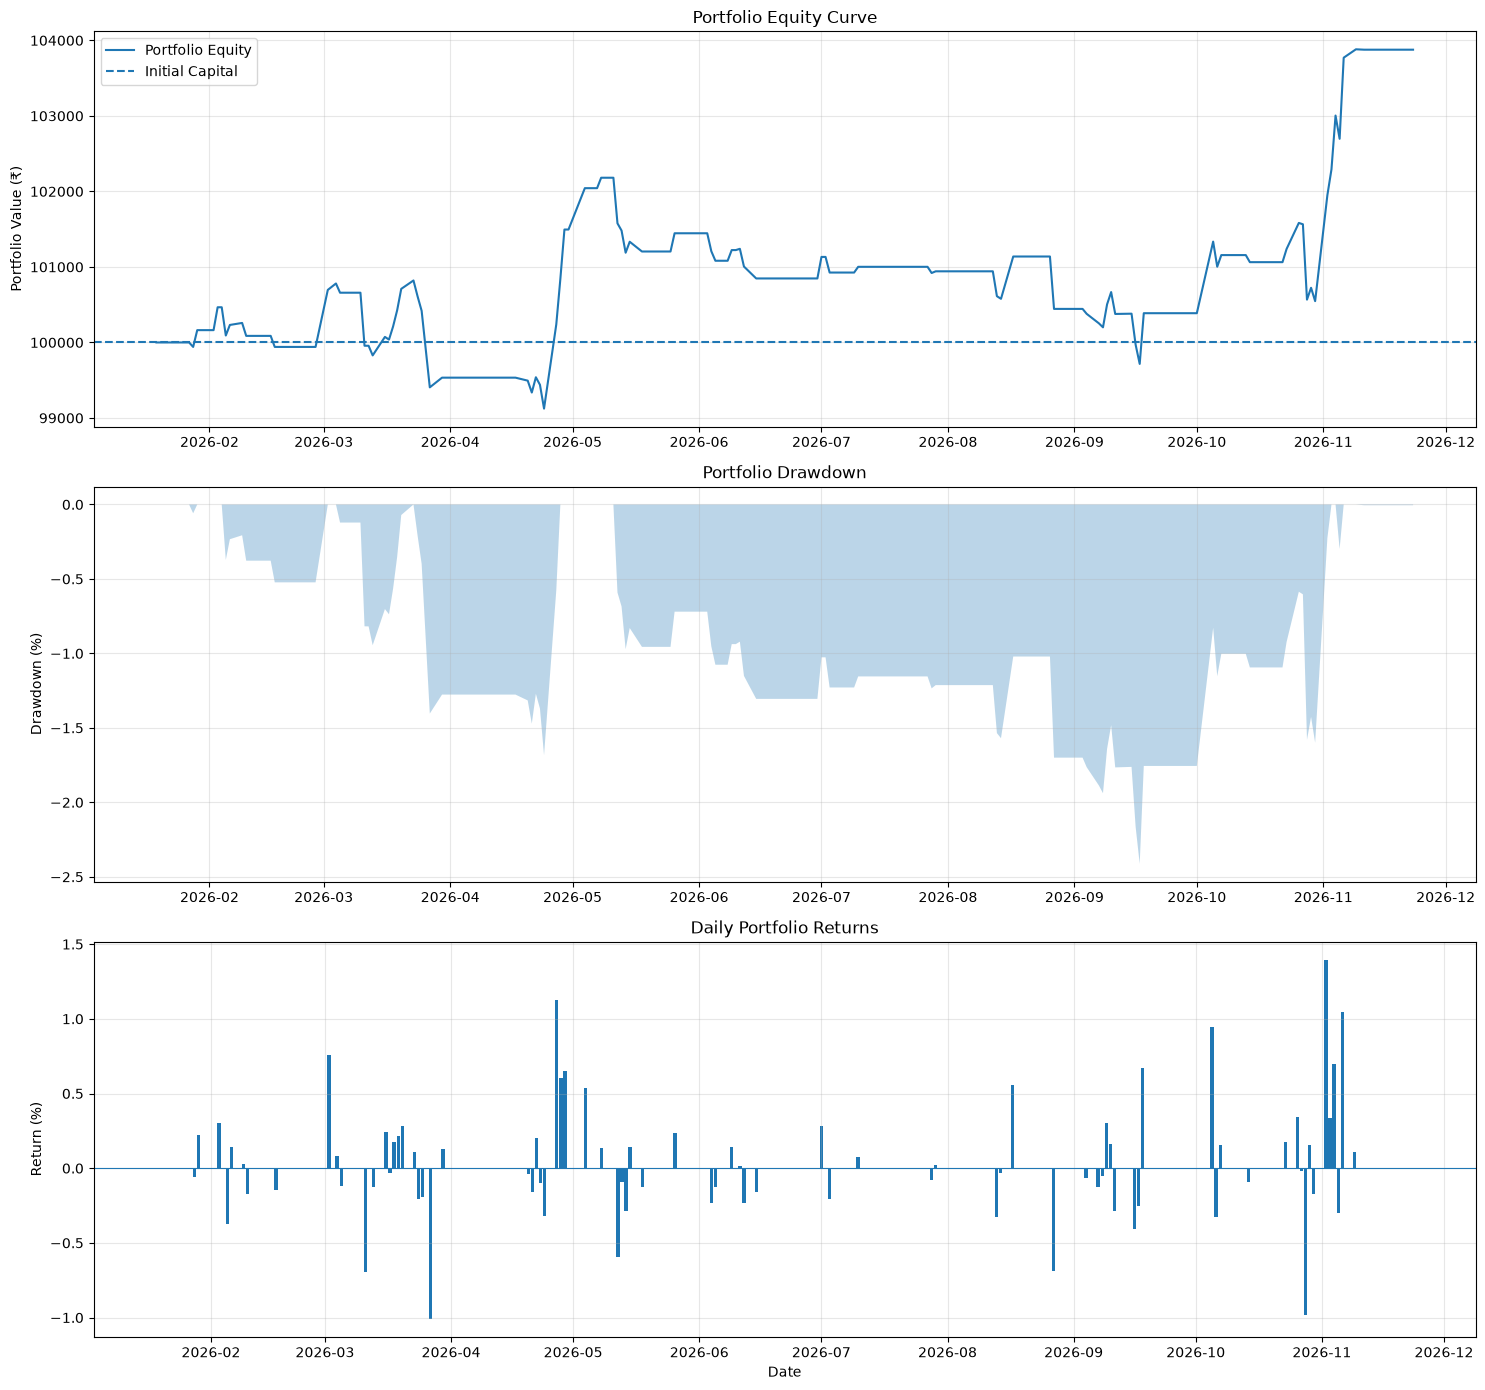

In [12]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 14)
)

# Equity curve
axes[0].plot(
    daily["Date"],
    daily["Reconstructed_Equity"],
    label="Portfolio Equity"
)

axes[0].axhline(
    INITIAL_CAPITAL,
    linestyle="--",
    label="Initial Capital"
)

axes[0].set_title("Portfolio Equity Curve")
axes[0].set_ylabel("Portfolio Value (₹)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Drawdown
axes[1].fill_between(
    daily["Date"],
    daily["Drawdown_Pct"],
    0,
    alpha=0.3
)

axes[1].set_title("Portfolio Drawdown")
axes[1].set_ylabel("Drawdown (%)")
axes[1].grid(alpha=0.3)

# Daily returns
axes[2].bar(
    daily["Date"],
    daily["Daily_Return_Pct"]
)

axes[2].axhline(0, linewidth=0.8)
axes[2].set_title("Daily Portfolio Returns")
axes[2].set_ylabel("Return (%)")
axes[2].set_xlabel("Date")
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "risk_management_dashboard.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
final_equity = daily["Reconstructed_Equity"].iloc[-1]

total_return_pct = (
    final_equity / INITIAL_CAPITAL - 1
) * 100

risk_scorecard = pd.DataFrame([{
    "Initial_Capital": INITIAL_CAPITAL,
    "Final_Capital": final_equity,
    "Net_Profit": final_equity - INITIAL_CAPITAL,
    "Total_Return_Pct": total_return_pct,
    "Total_Trades": len(trades),
    "Win_Rate_Pct": (
        (trades["Net_PnL"] > 0).mean() * 100
        if len(trades) else 0
    ),
    "Annualized_Return_Pct": annualized_return,
    "Annualized_Volatility_Pct": annualized_volatility,
    "Sharpe_Ratio": sharpe_ratio,
    "Sortino_Ratio": sortino_ratio,
    "Maximum_Drawdown_Pct": max_drawdown_pct,
    "Maximum_Consecutive_Losses": (
        streak_results["Maximum_Consecutive_Losses"]
    ),
    "Daily_Loss_Breaches": len(breach_days),
    "Risk_Budget_Exceeded_Trades": int(
        trades["Risk_Budget_Exceeded"].sum()
    ),
    "Historical_VaR_95_Pct": var_95_return * 100,
    "Historical_CVaR_95_Pct": cvar_95_return * 100
}])

display(risk_scorecard.T.rename(columns={0: "Value"}))

,Value
Initial_Capital,100000.000000
Final_Capital,103876.623670
Net_Profit,3876.623670
Total_Return_Pct,3.876624
Total_Trades,94.000000
Win_Rate_Pct,50.000000
Annualized_Return_Pct,4.715743
Annualized_Volatility_Pct,4.103496
Sharpe_Ratio,1.143404
Sortino_Ratio,1.962091


In [14]:
risk_scorecard.to_csv(
    REPORT_DIR / "risk_management_scorecard.csv",
    index=False
)

daily.to_csv(
    REPORT_DIR / "risk_adjusted_daily_portfolio.csv",
    index=False
)

instrument_risk.to_csv(
    REPORT_DIR / "instrument_risk_contribution.csv",
    index=False
)

daily_loss_summary.to_csv(
    REPORT_DIR / "daily_loss_limit_analysis.csv",
    index=False
)

risk_summary.to_csv(
    REPORT_DIR / "trade_risk_analysis.csv",
    index=False
)

volatility_summary.to_csv(
    REPORT_DIR / "volatility_and_risk_ratios.csv",
    index=False
)

streak_summary.to_csv(
    REPORT_DIR / "winning_losing_streak_analysis.csv",
    index=False
)

var_summary.to_csv(
    REPORT_DIR / "historical_var_cvar_analysis.csv",
    index=False
)

monthly_risk.to_csv(
    REPORT_DIR / "monthly_portfolio_risk_analysis.csv",
    index=False
)

print("Notebook 11 reports exported successfully.")

for file in sorted(REPORT_DIR.glob("*risk*.csv")):
    print("Saved:", file.name)

print("\nAdditional reports:")
for name in [
    "daily_loss_limit_analysis.csv",
    "trade_risk_analysis.csv",
    "volatility_and_risk_ratios.csv",
    "winning_losing_streak_analysis.csv",
    "historical_var_cvar_analysis.csv"
]:
    print(name)

Notebook 11 reports exported successfully.
Saved: instrument_risk_contribution.csv
Saved: monthly_portfolio_risk_analysis.csv
Saved: risk_adjusted_daily_portfolio.csv
Saved: risk_management_scorecard.csv
Saved: risk_return_analysis.csv
Saved: trade_risk_analysis.csv
Saved: volatility_and_risk_ratios.csv

Additional reports:
daily_loss_limit_analysis.csv
trade_risk_analysis.csv
volatility_and_risk_ratios.csv
winning_losing_streak_analysis.csv
historical_var_cvar_analysis.csv


In [15]:
print("=" * 70)
print("BHARATMARKET AI — NOTEBOOK 11")
print("RISK MANAGEMENT & PORTFOLIO ANALYTICS")
print("=" * 70)

print("\nPORTFOLIO")
print("-" * 45)
print(f"Initial Capital:          ₹{INITIAL_CAPITAL:,.2f}")
print(f"Final Capital:            ₹{final_equity:,.2f}")
print(f"Net Profit:               ₹{final_equity - INITIAL_CAPITAL:,.2f}")
print(f"Total Return:             {total_return_pct:.2f}%")

print("\nRISK METRICS")
print("-" * 45)
print(f"Annualized Volatility:    {annualized_volatility:.2f}%")
print(f"Sharpe Ratio:             {sharpe_ratio:.3f}")
print(f"Sortino Ratio:            {sortino_ratio:.3f}")
print(f"Maximum Drawdown:         {max_drawdown_pct:.2f}%")

print("\nRISK CONTROL")
print("-" * 45)
print(f"Daily Loss Limit:         {MAX_DAILY_LOSS_PCT:.2f}%")
print(f"Daily Limit Breaches:     {len(breach_days)}")
print(
    "Risk Budget Breaches:    "
    f"{int(trades['Risk_Budget_Exceeded'].sum())}"
)
print(
    "Maximum Losing Streak:   "
    f"{streak_results['Maximum_Consecutive_Losses']}"
)

print("\nRISK ESTIMATION")
print("-" * 45)
print(f"Historical VaR (95%):     {var_95_return * 100:.3f}%")
print(f"Historical CVaR (95%):    {cvar_95_return * 100:.3f}%")

print("\nDATA")
print("-" * 45)
print("Trading sessions:", len(daily))
print("Trades:", len(trades))
print("Instruments analysed:", trades["Instrument"].nunique())

print("\n" + "=" * 70)
print("NOTEBOOK 11 EXECUTION COMPLETED")
print("=" * 70)

BHARATMARKET AI — NOTEBOOK 11
RISK MANAGEMENT & PORTFOLIO ANALYTICS

PORTFOLIO
---------------------------------------------
Initial Capital:          ₹100,000.00
Final Capital:            ₹103,876.62
Net Profit:               ₹3,876.62
Total Return:             3.88%

RISK METRICS
---------------------------------------------
Annualized Volatility:    4.10%
Sharpe Ratio:             1.143
Sortino Ratio:            1.962
Maximum Drawdown:         -2.41%

RISK CONTROL
---------------------------------------------
Daily Loss Limit:         2.00%
Daily Limit Breaches:     0
Risk Budget Breaches:    1
Maximum Losing Streak:   4

RISK ESTIMATION
---------------------------------------------
Historical VaR (95%):     -0.295%
Historical CVaR (95%):    -0.547%

DATA
---------------------------------------------
Trading sessions: 208
Trades: 94
Instruments analysed: 3

NOTEBOOK 11 EXECUTION COMPLETED
